# StockMate: Product Demand Forecasting

## Question 1: Machine Learning Approach
**Objective:** Predict next week’s sales using the UCI Online Retail dataset.

**Approach:** Supervised regression learns from known sales quantities to predict a number. Random Forest averages predictions from multiple decision trees.

**Inputs:** Previous three weeks’ sales, their average and forecast month.

### Data Understanding

The dataset is examined to identify data types, missing values, duplicate records and invalid transactions before cleaning.

In [4]:
import pandas as pd

# Load the Online Retail dataset
df = pd.read_excel("/content/Online Retail.xlsx")

# Display the first five transactions
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check the data types of each column
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (541909, 8)

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


In [6]:

# Check cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C").sum()

# Check negative or zero quantities
negative_qty = (df["Quantity"] < 0).sum()
zero_qty = (df["Quantity"] == 0).sum()

# Check invalid prices
invalid_prices = (df["UnitPrice"] <= 0).sum()

print("Cancelled invoices:", cancelled)
print("Negative quantities:", negative_qty)
print("Zero quantities:", zero_qty)
print("Zero or negative prices:", invalid_prices)


Cancelled invoices: 9288
Negative quantities: 10624
Zero quantities: 0
Zero or negative prices: 2517



## Question 2: Data Cleaning

The original dataset contained 541,909 rows.

We cleaned the data by:
- Removing duplicate records.
- Removing cancelled transactions.
- Removing negative or zero quantities and prices.
- Removing records with missing product descriptions.

We kept missing CustomerID values because they are not needed to predict product sales.

**Result:** 524,878 rows remained after cleaning.

**Purpose:** To prepare reliable sales records for our model.


In [7]:

# Create a copy to preserve the original dataset
df_clean = df.copy()

print("Original rows:", len(df_clean))

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove cancelled transactions
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Keep only positive prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Remove records without a product description
df_clean = df_clean.dropna(subset=["Description"])

# Display cleaning results
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

display(df_clean.head())


Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Dataset Reduction
We selected 30 of 3,922 products by active weeks and sales in the training period only, avoiding use of future test data. This left 30,716 transactions.

In [8]:
# Preserve the full cleaned dataset
df_full = df_clean.copy()

# Standardize product codes
df_full["StockCode"] = df_full["StockCode"].astype(str)

# Convert transaction dates into weeks
df_full["Week"] = (
    df_full["InvoiceDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Identify complete weeks and training cutoff
weeks = sorted(df_full["Week"].unique())[1:-1]
split_date = weeks[int(len(weeks) * 0.8)]

# Use training-period records to select physical products
selection_data = df_full[
    (df_full["Week"] >= weeks[0]) &
    (df_full["Week"] < split_date) &
    (df_full["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*"))
]

# Summarize each product
product_summary = selection_data.groupby("StockCode").agg(
    Description=("Description", lambda x: x.mode().iloc[0]),
    Active_Weeks=("Week", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

# Select 30 consistently selling products
selected_products = product_summary.sort_values(
    ["Active_Weeks", "Total_Quantity"],
    ascending=False
).head(30)

# Retain historical transactions for selected products
df_reduced = df_full[
    df_full["StockCode"].isin(selected_products.index)
].copy()

# Display results
print("Original cleaned rows:", len(df_full))
print("Reduced dataset rows:", len(df_reduced))
print("Original products:", df_full["StockCode"].nunique())
print("Selected products:", df_reduced["StockCode"].nunique())
print("Training cutoff:", split_date)

display(selected_products)

Original cleaned rows: 524878
Reduced dataset rows: 30716
Original products: 3922
Selected products: 30
Training cutoff: 2011-09-25 00:00:00


,Description,Active_Weeks,Total_Quantity
StockCode,,,
85099B,JUMBO BAG RED RETROSPOT,40,32664
22197,SMALL POPCORN HOLDER,40,29515
21212,PACK OF 72 RETROSPOT CAKE CASES,40,28890
85123A,WHITE HANGING HEART T-LIGHT HOLDER,40,28165
84879,ASSORTED COLOUR BIRD ORNAMENT,40,24689
15036,ASSORTED COLOURS SILK FAN,40,21700
21977,PACK OF 60 PINK PAISLEY CAKE CASES,40,20727
22616,PACK OF 12 LONDON TISSUES,40,19367
22492,MINI PAINT SET VINTAGE,40,18558


## Question 2: Exploratory Data Analysis (EDA)
EDA uses graphs to identify patterns in sales before training.

In [9]:
import matplotlib.pyplot as plt

# Use the reduced dataset
eda_df = df_reduced.copy()

# Use consistent product descriptions
eda_df["Description"] = eda_df["StockCode"].map(
    selected_products["Description"]
)

# Observation 1: Number of unique products
print("Unique products:", eda_df["StockCode"].nunique())

# Observation 2: Top 10 products by quantity sold
top_products = (
    eda_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Best-Selling Products:")
print(top_products)

# Observation 3: Monthly sales quantities
eda_df["Month"] = eda_df["InvoiceDate"].dt.to_period("M")

monthly_sales = eda_df.groupby("Month")["Quantity"].sum()

print("\nMonthly Sales Quantities:")
print(monthly_sales)

# Observation 4: Top 10 countries by quantity sold
country_sales = (
    eda_df.groupby("Country")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Countries by Quantity Sold:")
print(country_sales)

Unique products: 30

Top 10 Best-Selling Products:
Description
SMALL POPCORN HOLDER                  56898
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37641
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
MINI PAINT SET VINTAGE                26633
PACK OF 12 LONDON TISSUES             26119
PACK OF 60 PINK PAISLEY CAKE CASES    24820
VICTORIAN GLASS HANGING T-LIGHT       24275
ASSORTED COLOURS SILK FAN             23826
Name: Quantity, dtype: int64

Monthly Sales Quantities:
Month
2010-12    47631
2011-01    39974
2011-02    42259
2011-03    61838
2011-04    48728
2011-05    65539
2011-06    48042
2011-07    49888
2011-08    61575
2011-09    57686
2011-10    54684
2011-11    70536
2011-12    20835
Freq: M, Name: Quantity, dtype: int64

Top 10 Countries by Quantity Sold:
Country
United Kingdom    568171
Netherlands        24568
EIRE               17262
France             12892
Germany             9666
Austral

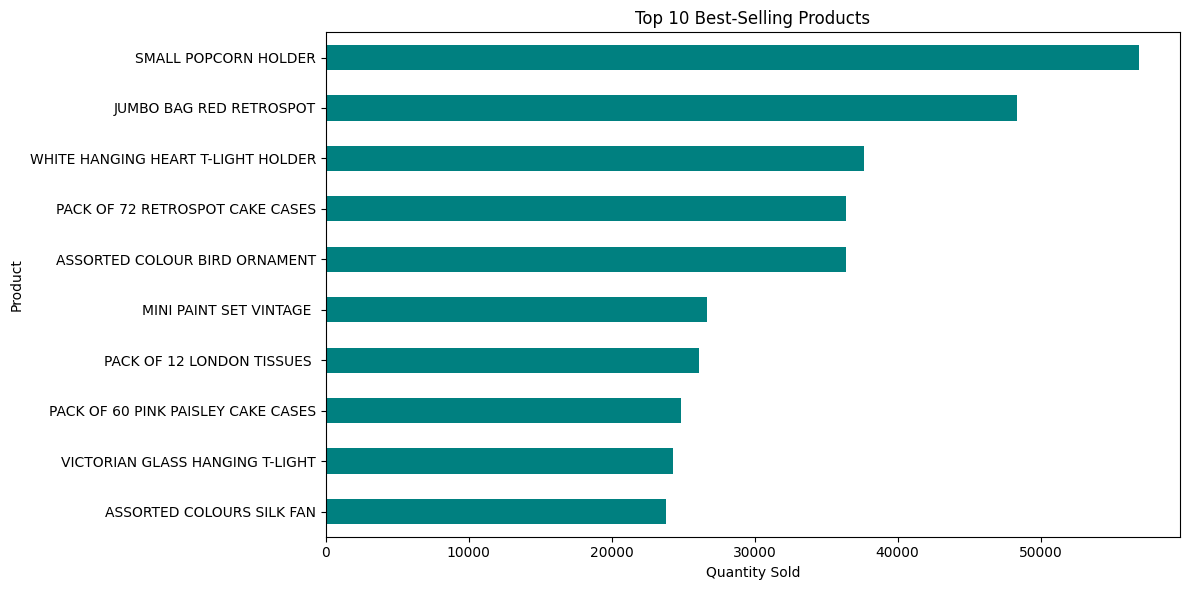

In [10]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind="barh", color="teal"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

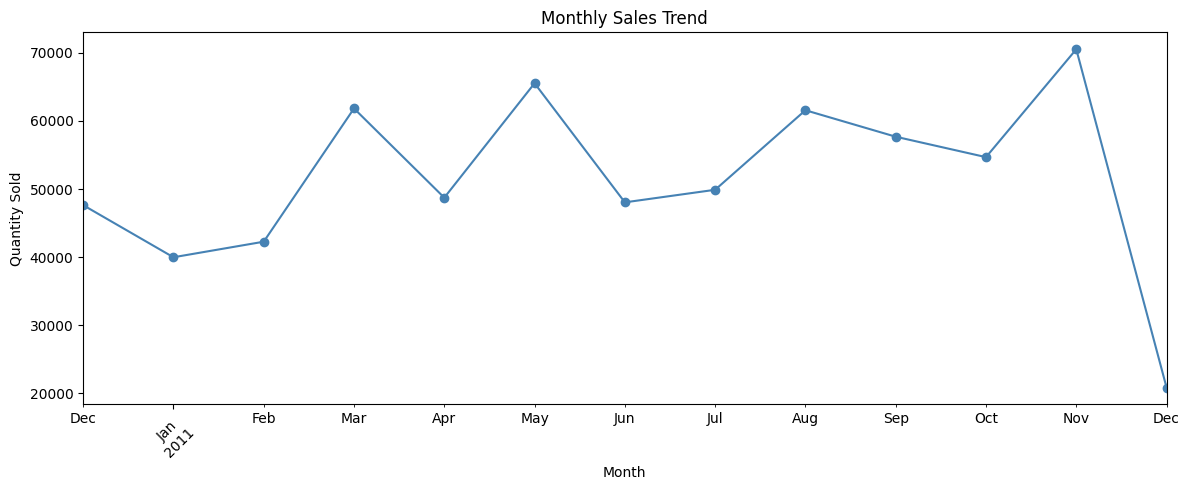

In [11]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line", marker="o", color="steelblue"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

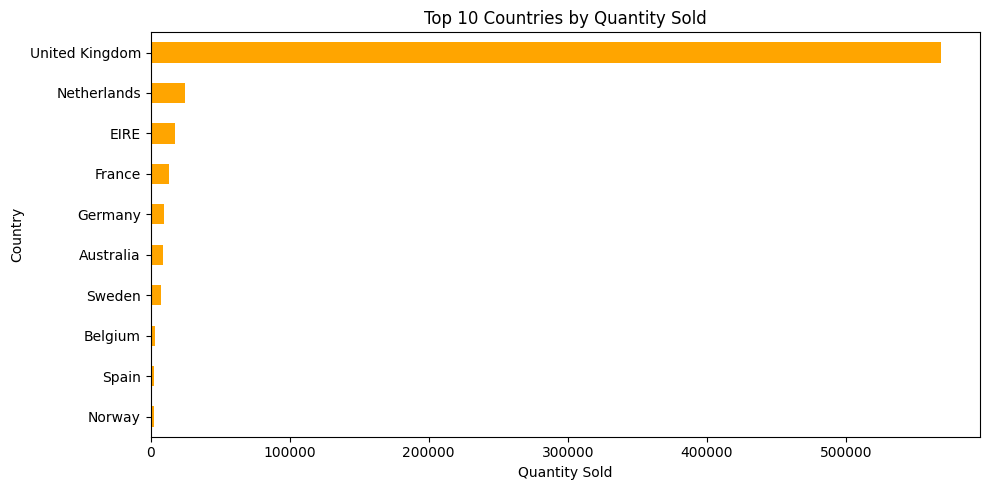

In [12]:
plt.figure(figsize=(10, 5))

country_sales.sort_values().plot(
    kind="barh", color="orange"
)

plt.title("Top 10 Countries by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

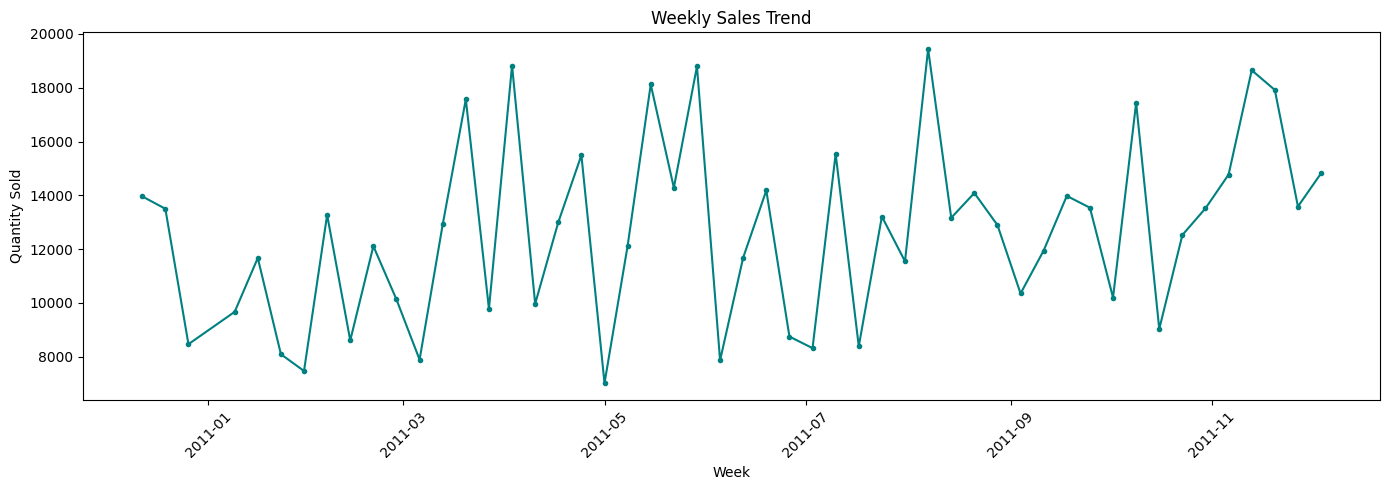

In [13]:
weekly_sales_trend = (
    eda_df[eda_df["Week"].isin(weeks)]
    .groupby("Week")["Quantity"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    weekly_sales_trend.index,
    weekly_sales_trend.values,
    marker="o",
    markersize=3,
    color="teal"
)

plt.title("Weekly Sales Trend")
plt.xlabel("Week")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### EDA Observations
- Small Popcorn Holder sold the most (56,898 units), followed by Jumbo Bag Red Retrospot (48,371).
- November 2011 had the highest monthly sales (70,536); December is incomplete.
- The UK recorded the most sales (568,171 units).
- Weekly demand fluctuates, making forecasting useful.

### Product Categorization
Six categories organize the products in StockMate. They are not model inputs.

Uncategorized products: 0
Category
Kitchen & Dining        8
Home Decor              7
Bags & Storage          6
Party & Baking          5
Toys & Hobbies          3
Personal Accessories    1
Name: count, dtype: int64


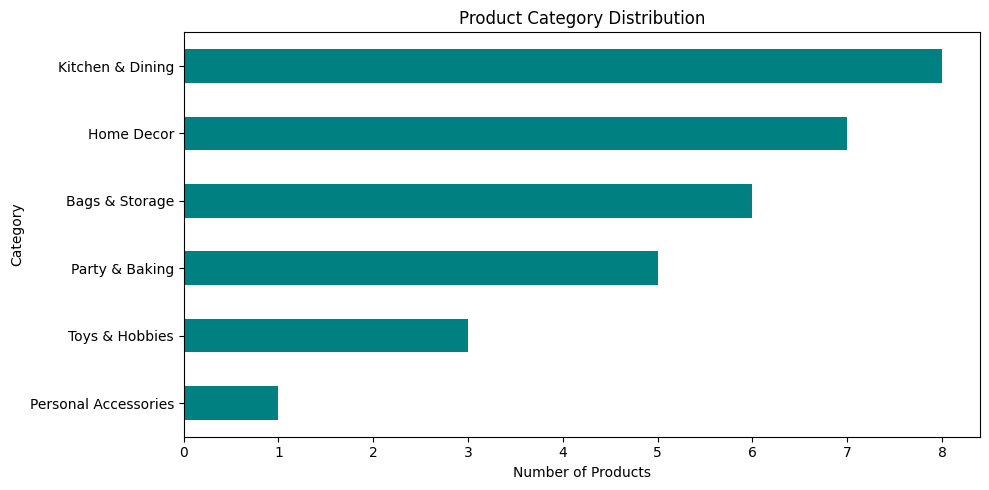

In [14]:
# Manually categorize the selected products
category_groups = {
    "Kitchen & Dining": [
        "22197", "22616", "22151", "22961",
        "22629", "21080", "22423", "84992"
    ],
    "Home Decor": [
        "85123A", "84879", "22178", "84755",
        "84946", "71459", "47566"
    ],
    "Bags & Storage": [
        "85099B", "20725", "22386",
        "22355", "20724", "21931"
    ],
    "Party & Baking": [
        "21212", "21977", "84991",
        "21213", "21975"
    ],
    "Toys & Hobbies": [
        "22492", "22693", "21915"
    ],
    "Personal Accessories": [
        "15036"
    ]
}

# Create product-to-category mapping
category_map = {
    code: category
    for category, codes in category_groups.items()
    for code in codes
}

# Assign categories
df_reduced["Category"] = df_reduced["StockCode"].map(
    category_map
)

selected_products["Category"] = (
    selected_products.index.map(category_map)
)

# Check for uncategorized products
print("Uncategorized products:",
      selected_products["Category"].isna().sum())

# Count unique products in each category
category_counts = (
    selected_products["Category"].value_counts()
)

print(category_counts)

# Plot category distribution
plt.figure(figsize=(10, 5))

category_counts.sort_values().plot(
    kind="barh", color="teal"
)

plt.title("Product Category Distribution")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Question 3: Model Development and Validation
### Data Preparation
Group sales by product and week, exclude incomplete boundary weeks and fill missing weeks with zero recorded sales (1,560 records).

In [15]:
# Create a weekly sales dataset using complete weeks
weekly_sales = (
    df_reduced[df_reduced["Week"].isin(weeks)]
    .groupby(["StockCode", "Week"])["Quantity"]
    .sum()
    .reset_index()
)

# Rename columns for clarity
weekly_sales.columns = [
    "StockCode",
    "Week",
    "WeeklySales"
]

print("Weekly dataset shape:", weekly_sales.shape)

display(weekly_sales.head(10))

Weekly dataset shape: (1530, 3)


,StockCode,Week,WeeklySales
0,15036,2010-12-12,21
1,15036,2010-12-19,35
2,15036,2010-12-26,30
3,15036,2011-01-09,18
4,15036,2011-01-16,159
5,15036,2011-01-23,39
6,15036,2011-01-30,112
7,15036,2011-02-06,1913
8,15036,2011-02-13,68
9,15036,2011-02-20,762


In [16]:
# Create a complete weekly timeline
all_weeks = pd.date_range(
    start=weeks[0],
    end=weeks[-1],
    freq="W-SUN"
)

# Create every product-week combination
full_index = pd.MultiIndex.from_product(
    [selected_products.index, all_weeks],
    names=["StockCode", "Week"]
)

# Fill missing weeks with zero sales
weekly_complete = (
    weekly_sales
    .set_index(["StockCode", "Week"])
    .reindex(full_index, fill_value=0)
    .reset_index()
    .sort_values(["StockCode", "Week"])
    .reset_index(drop=True)
)

# Display the results
print("Before filling:", weekly_sales.shape)
print("After filling:", weekly_complete.shape)
print("Unique products:", weekly_complete["StockCode"].nunique())
print("Number of weeks:", weekly_complete["Week"].nunique())
print("Zero-sales weeks:", (weekly_complete["WeeklySales"] == 0).sum())

# Show the first 12 weeks for Small Popcorn Holder
display(
    weekly_complete[
        weekly_complete["StockCode"] == "22197"
    ].head(12)
)

Before filling: (1530, 3)
After filling: (1560, 3)
Unique products: 30
Number of weeks: 52
Zero-sales weeks: 30


,StockCode,Week,WeeklySales
624,22197,2010-12-12,1012
625,22197,2010-12-19,980
626,22197,2010-12-26,252
627,22197,2011-01-02,0
628,22197,2011-01-09,807
629,22197,2011-01-16,344
630,22197,2011-01-23,261
631,22197,2011-01-30,351
632,22197,2011-02-06,107
633,22197,2011-02-13,239


### Feature Engineering
Create inputs from past sales: three weekly quantities, their average and the forecast month. The target is actual weekly sales. Removing weeks without enough history leaves 1,470 records.

In [17]:

# Step 8: Feature Engineering

# Sort the data by product and week
model_data = weekly_complete.sort_values(
    ["StockCode", "Week"]
).copy()

# Group sales by product
product_sales = model_data.groupby("StockCode")["WeeklySales"]

# Create historical sales features
model_data["Sales_Last_Week"] = product_sales.shift(1)

model_data["Sales_2_Weeks_Ago"] = product_sales.shift(2)

model_data["Sales_3_Weeks_Ago"] = product_sales.shift(3)

# Calculate average sales over the previous 3 weeks
model_data["Average_Last_3_Weeks"] = (
    model_data.groupby("StockCode")["WeeklySales"]
    .transform(
        lambda x: x.shift(1).rolling(3).mean()
    )
)

# Add calendar information
model_data["Month"] = model_data["Week"].dt.month

# Remove rows without enough sales history
model_data = model_data.dropna().copy()

# Display results
print("Model dataset shape:", model_data.shape)

display(model_data.head(10))


Model dataset shape: (1470, 8)


,StockCode,Week,WeeklySales,Sales_Last_Week,Sales_2_Weeks_Ago,Sales_3_Weeks_Ago,Average_Last_3_Weeks,Month
3,15036,2011-01-02,0,30.0,35.0,21.0,28.666667,1
4,15036,2011-01-09,18,0.0,30.0,35.0,21.666667,1
5,15036,2011-01-16,159,18.0,0.0,30.0,16.000000,1
6,15036,2011-01-23,39,159.0,18.0,0.0,59.000000,1
7,15036,2011-01-30,112,39.0,159.0,18.0,72.000000,1
8,15036,2011-02-06,1913,112.0,39.0,159.0,103.333333,2
9,15036,2011-02-13,68,1913.0,112.0,39.0,688.000000,2
10,15036,2011-02-20,762,68.0,1913.0,112.0,697.666667,2
11,15036,2011-02-27,128,762.0,68.0,1913.0,914.333333,2
12,15036,2011-03-06,91,128.0,762.0,68.0,319.333333,3


### Training and Testing
Train on earlier weeks (1,140 records) and test on later weeks (330 records) to avoid learning from future sales.

In [18]:
# Define input features
features = [
    "Sales_Last_Week",
    "Sales_2_Weeks_Ago",
    "Sales_3_Weeks_Ago",
    "Average_Last_3_Weeks",
    "Month"
]

# Define the target variable
target = "WeeklySales"

# Split data chronologically
train_data = model_data[
    model_data["Week"] < split_date
].copy()

test_data = model_data[
    model_data["Week"] >= split_date
].copy()

# Separate inputs and target
X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

# Display results
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(train_data["Week"].min(), "to", train_data["Week"].max())

print("\nTesting period:")
print(test_data["Week"].min(), "to", test_data["Week"].max())

Training records: 1140
Testing records: 330

Training period:
2011-01-02 00:00:00 to 2011-09-18 00:00:00

Testing period:
2011-09-25 00:00:00 to 2011-12-04 00:00:00


### Model Training
Train 100 decision trees with a fixed random seed for reproducibility.

In [19]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Model Evaluation
- **MAE:** Average absolute error in units.
- **RMSE:** Gives larger errors more weight.
- **R²:** Measures fit relative to predicting the mean; not percentage accuracy.

In [20]:
#Member 3
# Step 11: Evaluate Random Forest Regression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Generate predictions
train_predictions = rf_model.predict(X_train)
test_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

# Evaluate training performance
train_mae, train_rmse, train_r2 = evaluate_model(
    y_train, train_predictions
)

# Evaluate testing performance
test_mae, test_rmse, test_r2 = evaluate_model(
    y_test, test_predictions
)

# Display results
print("TRAINING PERFORMANCE")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("R2 Score:", round(train_r2, 4))

print("\nTESTING PERFORMANCE")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 4))


TRAINING PERFORMANCE
MAE: 92.73
RMSE: 143.11
R2 Score: 0.8609

TESTING PERFORMANCE
MAE: 283.31
RMSE: 473.99
R2 Score: 0.1808


Training MAE (92.73) is much lower than test MAE (283.31), suggesting overfitting: learning training data too closely.

In [21]:
# Compare actual and predicted weekly sales
prediction_results = test_data[
    ["StockCode", "Week", "WeeklySales"]
].copy()

prediction_results["PredictedSales"] = test_predictions.round(2)

display(prediction_results.head(10))

,StockCode,Week,WeeklySales,PredictedSales
41,15036,2011-09-25,93,232.49
42,15036,2011-10-02,30,377.20
43,15036,2011-10-09,721,437.76
44,15036,2011-10-16,224,275.68
45,15036,2011-10-23,194,264.65
46,15036,2011-10-30,101,342.85
47,15036,2011-11-06,83,268.70
48,15036,2011-11-13,107,449.43
49,15036,2011-11-20,104,402.28
50,15036,2011-11-27,237,308.27


### Baseline
Use last week’s sales as a simple reference prediction.

In [22]:

# Step 12: Compare Random Forest with a baseline

# Baseline: predict the same sales as last week
baseline_predictions = X_test["Sales_Last_Week"]

# Evaluate baseline performance
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Display comparison
comparison = pd.DataFrame({
    "Model": ["Baseline (Last Week)", "Random Forest"],
    "MAE": [baseline_mae, test_mae],
    "RMSE": [baseline_rmse, test_rmse],
    "R2": [baseline_r2, test_r2]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))


MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2
0,Baseline (Last Week),288.3485,479.1651,0.1628
1,Random Forest,283.3052,473.9871,0.1808


### Hyperparameter Tuning
Test 12 combinations of tree depth and minimum leaf size. Three chronological cross-validation folds train on earlier weeks and validate on later weeks. Select the lowest average validation MAE without using test data.

In [23]:
# Step 13: Hyperparameter Tuning and Time-Series Cross-Validation

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import ParameterGrid
import numpy as np
import pandas as pd

# Sort training records chronologically
cv_data = train_data.sort_values("Week").copy()

# Get unique training weeks
cv_weeks = np.array(sorted(cv_data["Week"].unique()))

tscv = TimeSeriesSplit(n_splits=3)

# Define model configurations to test
param_grid = {
    "n_estimators": [100],
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [1, 5, 10]
}

results = []

# Test each configuration
for params in ParameterGrid(param_grid):

    cv_scores = []

    for train_idx, val_idx in tscv.split(cv_weeks):

        train_weeks = cv_weeks[train_idx]
        val_weeks = cv_weeks[val_idx]

        fold_train = cv_data[
            cv_data["Week"].isin(train_weeks)
        ]

        fold_val = cv_data[
            cv_data["Week"].isin(val_weeks)
        ]

        model = RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            fold_train[features],
            fold_train[target]
        )

        predictions = model.predict(
            fold_val[features]
        )

        mae = mean_absolute_error(
            fold_val[target], predictions
        )

        cv_scores.append(mae)

    results.append({
        **params,
        "Average_CV_MAE": np.mean(cv_scores)
    })

# Rank configurations by validation error
tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    "Average_CV_MAE"
).reset_index(drop=True)

print("HYPERPARAMETER TUNING RESULTS")

display(tuning_results.round(4))

# Select the best configuration
best_result = min(
    results,
    key=lambda x: x["Average_CV_MAE"]
)

best_params = {
    key: best_result[key]
    for key in param_grid
}

print("\nBest parameters:", best_params)

print(
    "Best Average CV MAE:",
    round(best_result["Average_CV_MAE"], 2)
)

HYPERPARAMETER TUNING RESULTS


,max_depth,min_samples_leaf,n_estimators,Average_CV_MAE
0,5.0,10,100,245.2050
1,NaN,10,100,245.8670
2,15.0,10,100,245.8682
3,10.0,10,100,245.9623
4,5.0,5,100,246.3402
5,5.0,1,100,247.7977
6,NaN,5,100,249.6446
7,15.0,5,100,249.6790
8,10.0,5,100,249.7681
9,10.0,1,100,256.3544



Best parameters: {'n_estimators': 100, 'max_depth': 5, 'min_samples_leaf': 10}
Best Average CV MAE: 245.21


### Optimized Model
Best settings: 100 trees, depth 5 and minimum 10 samples per leaf (validation MAE 245.21). These limits reduce model complexity.

In [24]:
# Step 14: Train the optimized Random Forest model

optimized_rf = RandomForestRegressor(
    **best_params,
    random_state=42,
    n_jobs=-1
)

# Train the optimized model
optimized_rf.fit(X_train, y_train)

# Generate predictions
optimized_train_predictions = optimized_rf.predict(X_train)
optimized_test_predictions = optimized_rf.predict(X_test)

# Evaluate training performance
opt_train_mae, opt_train_rmse, opt_train_r2 = evaluate_model(
    y_train, optimized_train_predictions
)

# Evaluate testing performance
opt_test_mae, opt_test_rmse, opt_test_r2 = evaluate_model(
    y_test, optimized_test_predictions
)

print("OPTIMIZED TRAINING PERFORMANCE")
print("MAE:", round(opt_train_mae, 2))
print("RMSE:", round(opt_train_rmse, 2))
print("R2 Score:", round(opt_train_r2, 4))

print("\nOPTIMIZED TESTING PERFORMANCE")
print("MAE:", round(opt_test_mae, 2))
print("RMSE:", round(opt_test_rmse, 2))
print("R2 Score:", round(opt_test_r2, 4))

OPTIMIZED TRAINING PERFORMANCE
MAE: 216.73
RMSE: 340.63
R2 Score: 0.212

OPTIMIZED TESTING PERFORMANCE
MAE: 262.35
RMSE: 465.17
R2 Score: 0.211


In [25]:
# Compare baseline, original and optimized models

final_comparison = pd.DataFrame({
    "Model": [
        "Baseline (Last Week)",
        "Original Random Forest",
        "Optimized Random Forest"
    ],
    "MAE": [
        baseline_mae,
        test_mae,
        opt_test_mae
    ],
    "RMSE": [
        baseline_rmse,
        test_rmse,
        opt_test_rmse
    ],
    "R2": [
        baseline_r2,
        test_r2,
        opt_test_r2
    ]
})

print("FINAL MODEL PERFORMANCE COMPARISON")

display(final_comparison.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2
0,Baseline (Last Week),288.3485,479.1651,0.1628
1,Original Random Forest,283.3052,473.9871,0.1808
2,Optimized Random Forest,262.3526,465.1743,0.2110


The optimized model achieved test MAE 262.35, RMSE 465.17 and R² 0.2110. MAE improved by 9.02% over the baseline and 7.40% over the initial model. The smaller train/test error gap suggests reduced overfitting.

### Feature Importance
Measures how much each input contributes to tree splits overall.

FEATURE IMPORTANCE


,Feature,Importance
3,Average_Last_3_Weeks,0.521082
0,Sales_Last_Week,0.151549
4,Month,0.116431
2,Sales_3_Weeks_Ago,0.116049
1,Sales_2_Weeks_Ago,0.094890


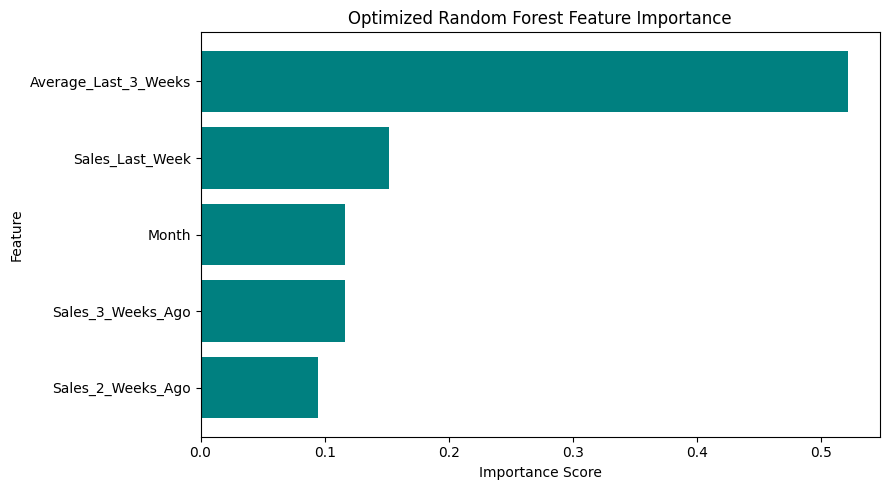

In [26]:
# Step 15: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores from the optimized model
importance = pd.DataFrame({
    "Feature": features,
    "Importance": optimized_rf.feature_importances_
})

# Sort from most important to least important
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
display(importance)

# Plot feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"],
    color="teal"
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Optimized Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The three-week average was most important (52.11%). These scores do not explain individual predictions.

## Question 4: Further Model Validation
We used a baseline, chronological cross-validation and hyperparameter tuning.

### Example Prediction and Explainable AI
Shapley contributions show how each input changes a prediction from a reference based on 100 training examples. The example uses historical sales and subtracts current stock from rounded demand (minimum zero).

In [27]:
import math

# Match the application's training-only reference sampling order.
reference_data = weekly_complete.sort_values('Week')
reference_data = reference_data[reference_data.Week < split_date].copy()
g = reference_data.groupby('StockCode').WeeklySales
for i, name in enumerate(features[:3], 1):
    reference_data[name] = g.shift(i)
reference_data[features[3]] = reference_data[features[:3]].mean(axis=1, skipna=False)
reference_data['Month'] = reference_data.Week.dt.month
reference = reference_data.dropna()[features].sample(
    n=min(100, len(reference_data.dropna())), random_state=42
).to_numpy()

def explain(x):
    # Exact Shapley enumeration over four groups; derived average always follows its inputs.
    # Coalition values average predictions over 100 historical reference scenarios.
    n = 4
    values = {}
    for mask in range(1 << n):
        rows = reference.copy()
        for j, col in enumerate([0,1,2,4]):
            if mask & (1 << j): rows[:,col] = x[col]
        rows[:,3] = rows[:,:3].mean(axis=1)
        values[mask] = float(optimized_rf.predict(pd.DataFrame(rows, columns=features)).mean())
    effects = []
    for j, name in enumerate(['Last week','Two weeks ago','Three weeks ago','Forecast month']):
        effect = 0
        for mask in range(1 << n):
            if mask & (1 << j): continue
            k = mask.bit_count()
            effect += math.factorial(k)*math.factorial(n-k-1)/math.factorial(n)*(values[mask | (1 << j)]-values[mask])
        effects.append({'name':name,'effect':effect})
    return {'reference':values[0], 'effects':effects}

# Demonstrate a historical forecast for Jumbo Bag Red Retrospot.
rows = weekly_complete[weekly_complete.StockCode == '85099B'].sort_values('Week')
a, b, c = rows.WeeklySales.tail(3).iloc[::-1].tolist()
forecast_week = rows.Week.iloc[-1] + pd.Timedelta(days=7)
x = [a, b, c, (a+b+c)/3, forecast_week.month]
prediction = float(optimized_rf.predict(pd.DataFrame([x], columns=features))[0])
explanation = explain(x)
print('Forecast week:', forecast_week.date())
print('Previous weekly sales:', a, b, c)
print('Predicted demand:', round(prediction, 2))
print('Reference prediction:', round(explanation['reference'], 2))
for item in explanation['effects']:
    print(item['name'], ':', round(item['effect'], 2))
assert np.isclose(prediction, explanation['reference'] + sum(e['effect'] for e in explanation['effects']))
print('Example restock quantity (445 units in stock):', max(0, round(prediction)-445))


Forecast week: 2011-12-11
Previous weekly sales: 1050 753 1602
Predicted demand: 689.66
Reference prediction: 371.78
Last week : 136.75
Two weeks ago : 45.7
Three weeks ago : 105.55
Forecast month : 29.88
Example restock quantity (445 units in stock): 245


## Model Deployment

The optimized Random Forest model is saved for use in StockMate to predict weekly product demand and support restocking decisions.

In [28]:
# Step 16: Export model and application data

import os
import joblib
import json
import sklearn

# Create export directory
os.makedirs("stockmate_exports", exist_ok=True)

# Export the optimized Random Forest model
joblib.dump(
    optimized_rf,
    "stockmate_exports/random_forest_model.pkl"
)

# Export product catalog
product_catalog = selected_products.reset_index()[
    ["StockCode", "Description", "Category"]
]

product_catalog.to_csv(
    "stockmate_exports/products.csv",
    index=False
)

# Export weekly sales history
weekly_complete.to_csv(
    "stockmate_exports/weekly_sales.csv",
    index=False
)

# Export feature importance
importance.to_csv(
    "stockmate_exports/feature_importance.csv",
    index=False
)

# Export model information
model_info = {
    "model_name": "Optimized Random Forest",
    "features": features,
    "parameters": best_params,
    "mae": float(opt_test_mae),
    "rmse": float(opt_test_rmse),
    "r2": float(opt_test_r2),
    "number_of_products": 30,
    "sklearn_version": sklearn.__version__
}

with open("stockmate_exports/model_info.json", "w") as file:
    json.dump(model_info, file, indent=4)

print("All files exported successfully!\n")

for filename in os.listdir("stockmate_exports"):
    print(filename)

All files exported successfully!

products.csv
feature_importance.csv
model_info.json
random_forest_model.pkl
weekly_sales.csv


## Conclusion

The optimized Random Forest achieved a testing MAE of 262.35 units, improving on the baseline by 9.02%. Although the model has limited predictive performance, it provides useful demand estimates for restocking decisions.